# 03, préparation des données

Phase 3 de CRISP-DM, résumée dans `docs/donnees.md`. Ce notebook calcule les indicateurs de Korhogo et de Bouaké à partir de la pluie IMERG et de la météo NASA POWER, avec leur tendance et leur variabilité interannuelle, en appelant `moteur/indicateurs.py` et `moteur/cultures.py` sans calcul propre.

L'humidité du sol SMAP, la végétation et l'occupation du sol MODIS et la pente SRTM seront ajoutées quand les extractions AppEEARS seront disponibles, ce qui attend le compte NASA Earthdata du responsable.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from moteur.cultures import courbes_kc_comparees, tableau_cultures
from moteur.donnees import altitude_power, lire_power, pluie_lieu, telecharger_point, voisinage_imerg
from moteur.indicateurs import (RegleSaison, ecart_recherches, evapotranspiration_serie, indicateurs_annuels,
                                indicateurs_cultures, resume_cultures, resume_interannuel, tendance_theil_sen,
                                troncature_debut)
from moteur.lieux import LIEUX_ETUDE as LIEUX

pd.set_option("display.precision", 3)
noms = {identifiant: lieu["nom"] for identifiant, lieu in LIEUX.items()}
donnees = {}
for identifiant, lieu in LIEUX.items():
    chemin_power = telecharger_point(lieu["lat"], lieu["lon"], "power")
    donnees[identifiant] = {"meteo": lire_power(chemin_power), "altitude": altitude_power(chemin_power),
                            "pluie": pluie_lieu(voisinage_imerg(lieu["lat"], lieu["lon"]))["moyenne"]}

## 1. Règles retenues

La pluie d'un lieu est la moyenne des neuf cases IMERG centrées sur la ville. Le début de saison suit la règle ci-dessous, et chaque culture comparée a une durée de cycle tirée du tableau 11 de FAO-56 et un coefficient cultural tiré de son tableau 12.

In [2]:
display(RegleSaison())
pd.DataFrame(tableau_cultures())

RegleSaison(recherche_debut='03-01', cumul_debut_mm=20.0, jours_cumul=3, jours_controle=30, sequence_seche_admise=7, jours_debut_saison=60)

,culture,comparée,durée,plage,ligne du tableau 11,stades,"Kc ini, mid, end"
0,coton,True,195.0,180 à 225,Egypt; Pakistan; Calif.,"(30, 50, 60, 55)","(0.35, 1.175, 0.6)"
1,maïs,True,125.0,125 à 180,Nigeria (humid),"(20, 35, 40, 30)","(0.3, 1.2, 0.475)"
2,sorgho,True,130.0,130 à 140,"USA, Pakis., Med.","(20, 35, 40, 35)","(0.3, 1.05, 0.55)"
3,mil,True,105.0,105 à 140,Pakistan,"(15, 25, 40, 25)","(0.3, 1.0, 0.3)"
4,arachide,True,130.0,130 à 140,West Africa,"(25, 35, 45, 25)","(0.4, 1.15, 0.6)"
5,niébé,True,110.0,110 à 110,Mediterranean,"(20, 30, 30, 30)","(0.4, 1.05, 0.475)"
6,soja,True,85.0,85 à 150,Tropics,"(15, 15, 40, 15)","(0.4, 1.15, 0.5)"
7,riz pluvial,True,150.0,150 à 180,Tropics; Mediterranean,"(30, 30, 60, 30)","(1.05, 1.2, 0.75)"
8,igname,False,NaN,NaN,absente du tableau 11 de FAO-56,None,None
9,mucuna,False,NaN,NaN,absente du tableau 11 de FAO-56,None,None


**Constat.** Le début est le premier jour, à partir du 1er mars, qui ouvre trois jours cumulant au moins 20 mm sans séquence sèche de plus de 7 jours dans les 30 jours suivants. Huit cultures ont une durée et un coefficient sourcés, de 85 jours pour le soja à 195 jours pour le coton. L'igname et le mucuna n'en ont pas.

**Analyse.** Les seuils du début de saison sont attribués à Sivakumar, 1988, par des sources secondaires seulement, et les durées de FAO-56 sont générales, non propres aux variétés ivoiriennes. Ces choix sont donc visibles et modifiables, et chaque indicateur qui en dépend est de niveau `calcule`.

**Décision.** Les règles s'appliquent à l'identique aux deux villes, pour qu'elles restent comparables. L'igname et le mucuna restent hors de la comparaison chiffrée.

## 2. Indicateurs annuels, tendance et variabilité

Pour chaque année de 2001 à 2025, la pluie annuelle, l'évapotranspiration de référence FAO-56, leur rapport, qui est l'indice d'aridité, le jour de début de saison et la plus longue séquence sèche des 60 jours qui suivent. Le résumé donne la médiane, les quantiles 10 et 90 %, les extrêmes, la pente de Theil-Sen par décennie et la probabilité du test de Mann-Kendall.

Korhogo


,annees,mediane,q10,q90,min,max,pente_par_decennie,p_mann_kendall
pluie_annuelle_mm,25,1221.813,1033.149,1318.364,963.728,1374.486,13.618,0.797
et0_annuelle_mm,25,1929.968,1771.618,2013.711,1748.166,2089.336,-33.566,0.199
debut_jour,25,103.000,85.400,122.600,83.000,148.000,9.091,0.037
indice_aridite,25,0.626,0.516,0.730,0.499,0.757,0.010,0.691
sequence_seche_debut_jours,25,6.000,4.000,9.000,4.000,13.000,0.000,0.738


Bouaké


,annees,mediane,q10,q90,min,max,pente_par_decennie,p_mann_kendall
pluie_annuelle_mm,25,1119.853,901.198,1278.796,832.539,1665.324,60.052,0.072
et0_annuelle_mm,25,1529.278,1435.782,1632.889,1427.337,1730.894,-49.380,0.080
debut_jour,25,76.000,61.400,119.000,60.000,149.000,-5.714,0.350
indice_aridite,25,0.724,0.568,0.847,0.527,1.115,0.070,0.034
sequence_seche_debut_jours,25,6.000,4.400,9.000,4.000,10.000,1.111,0.015


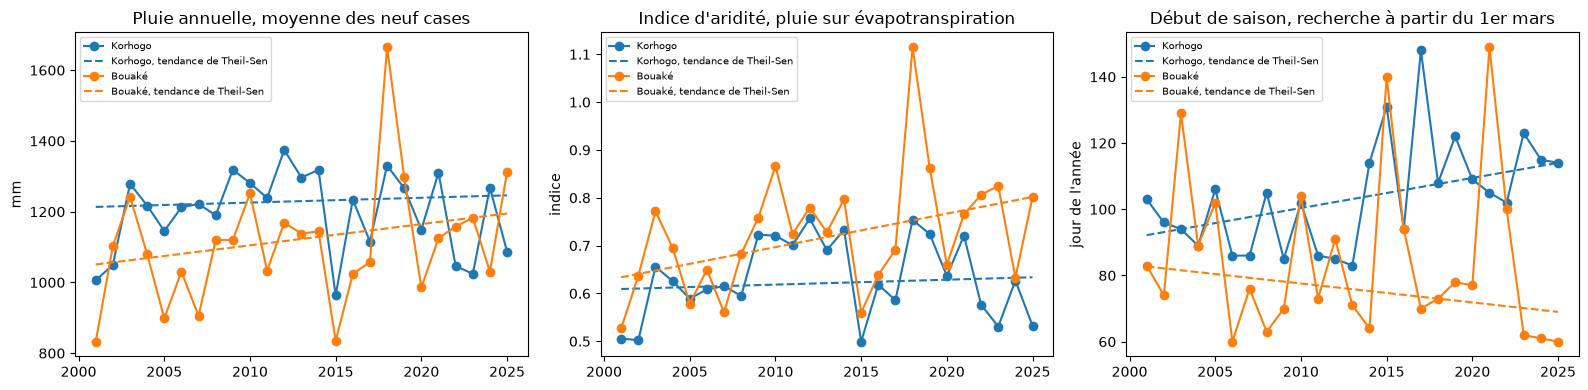

In [3]:
regle = RegleSaison()
annuels = {i: indicateurs_annuels(d["pluie"], d["meteo"], LIEUX[i]["lat"], d["altitude"], regle) for i, d in donnees.items()}
for identifiant, table in annuels.items():
    print(noms[identifiant])
    display(resume_interannuel(table))

figure, axes = plt.subplots(1, 3, figsize=(16, 4))
for couleur, (identifiant, table) in zip(["C0", "C1"], annuels.items()):
    for axe, colonne in zip(axes, ["pluie_annuelle_mm", "indice_aridite", "debut_jour"]):
        axe.plot(table.index, table[colonne], color=couleur, marker="o", label=noms[identifiant])
        axe.plot(table.index, tendance_theil_sen(table[colonne]), color=couleur, linestyle="--",
                 label=f"{noms[identifiant]}, tendance de Theil-Sen")
axes[0].set(title="Pluie annuelle, moyenne des neuf cases", ylabel="mm")
axes[1].set(title="Indice d'aridité, pluie sur évapotranspiration", ylabel="indice")
axes[2].set(title="Début de saison, recherche à partir du 1er mars", ylabel="jour de l'année")
for axe in axes:
    axe.legend(fontsize=7)
plt.tight_layout()
plt.show()

**Constat.** La pluie annuelle médiane vaut 1 221,8 mm à Korhogo, de 1 033,1 à 1 318,4 mm entre les quantiles 10 et 90 %, et 1 119,9 mm à Bouaké, de 901,2 à 1 278,8 mm. L'évapotranspiration médiane vaut 1 930,0 mm et 1 529,3 mm, si bien que l'indice d'aridité médian est de 0,626 à Korhogo et de 0,724 à Bouaké. Aucune tendance de la pluie n'est significative au seuil de 5 %, avec +13,618 mm par décennie et p = 0,797 à Korhogo, +60,052 mm et p = 0,072 à Bouaké. Le début de saison recule de 9,091 jours par décennie à Korhogo, p = 0,037. À Bouaké, l'indice d'aridité augmente de 0,070 par décennie, p = 0,034, et la séquence sèche de début de saison s'allonge de 1,111 jour, p = 0,015.

**Analyse.** Korhogo reçoit plus de pluie que Bouaké selon IMERG mais évapore davantage, et reste plus aride. Les trois tendances significatives sont fragiles. Avec cinq indicateurs testés par lieu, la probabilité qu'au moins un soit significatif par hasard vaut environ 23 %. Le recul du début à Korhogo dépend aussi de la date de recherche, et le début de Bouaké est tronqué, comme le montre la section suivante.

**Décision.** Les indicateurs sont présentés avec leur plage interannuelle. Aucune tendance n'est affirmée comme un changement du climat, ni dans l'outil ni dans le pitch, tant qu'elle n'est pas confirmée.

## 3. Début de saison et troncature par le 1er mars

Une recherche témoin à partir du 1er janvier montre ce que la recherche du 1er mars ne voit pas. Une recherche à partir du 1er février mesure ce que le 1er mars retire.

Korhogo


,troncature,1er mars contre 1er février
annees,25.0,25.00
annees_differentes,NaN,1.00
debut_dans_les_7_jours,0.0,NaN
debut_entre_7_et_13_jours,0.0,NaN
debut_le_jour_de_recherche,0.0,NaN
debut_temoin_avant_la_recherche,1.0,NaN
ecart_max_jours,NaN,56.00
ecart_median_jours,NaN,0.00
ecart_moyen_jours,NaN,2.24
mediane_precoce,NaN,102.00


Bouaké


,troncature,1er mars contre 1er février
annees,25.0,25.00
annees_differentes,NaN,10.00
debut_dans_les_7_jours,6.0,NaN
debut_entre_7_et_13_jours,5.0,NaN
debut_le_jour_de_recherche,2.0,NaN
debut_temoin_avant_la_recherche,11.0,NaN
ecart_max_jours,NaN,83.00
ecart_median_jours,NaN,0.00
ecart_moyen_jours,NaN,8.64
mediane_precoce,NaN,70.00


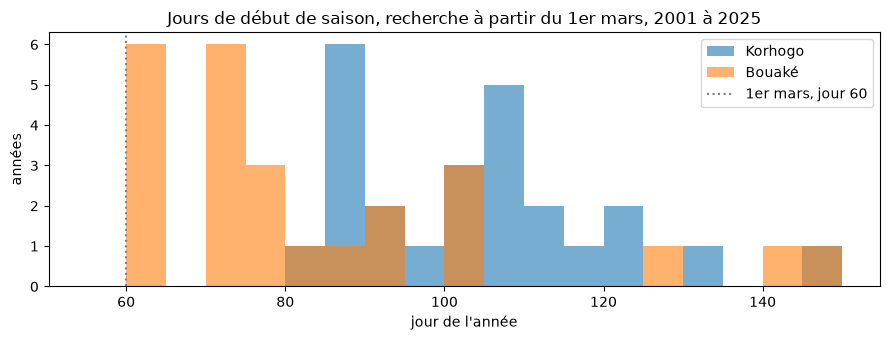

In [4]:
for identifiant, d in donnees.items():
    lieu = LIEUX[identifiant]
    temoin = indicateurs_annuels(d["pluie"], d["meteo"], lieu["lat"], d["altitude"], RegleSaison(recherche_debut="01-01"))
    fevrier = indicateurs_annuels(d["pluie"], d["meteo"], lieu["lat"], d["altitude"], RegleSaison(recherche_debut="02-01"))
    print(noms[identifiant])
    display(pd.DataFrame({"troncature": troncature_debut(annuels[identifiant]["debut_jour"], temoin["debut_jour"]),
                          "1er mars contre 1er février": ecart_recherches(annuels[identifiant]["debut_jour"],
                                                                         fevrier["debut_jour"])}))

figure, axe = plt.subplots(figsize=(9, 3.5))
for couleur, (identifiant, table) in zip(["C0", "C1"], annuels.items()):
    axe.hist(table["debut_jour"], bins=range(55, 155, 5), alpha=0.6, color=couleur, label=noms[identifiant])
axe.axvline(60, color="grey", linestyle=":", label="1er mars, jour 60")
axe.set(title="Jours de début de saison, recherche à partir du 1er mars, 2001 à 2025", xlabel="jour de l'année",
        ylabel="années")
axe.legend()
plt.tight_layout()
plt.show()

**Constat.** À Korhogo, aucun début ne tombe dans les 14 jours qui suivent le 1er mars, et la recherche témoin ne trouve qu'une année où la saison commence avant. À Bouaké, 2 débuts tombent le 1er mars même et 6 dans ses 7 premiers jours, et la recherche témoin trouve 11 années sur 25 où la saison commence avant le 1er mars. Une recherche à partir du 1er février change 10 années sur 25 à Bouaké, déplace la médiane du jour 76 au jour 70, soit du 17 au 11 mars, et le début de 8,64 jours en moyenne, jusqu'à 83 jours. À Korhogo, elle ne change qu'une année.

**Analyse.** Les débuts de Bouaké s'accumulent juste après le 1er mars, signe que la date de recherche coupe leur distribution près d'une année sur deux. Certains débuts de janvier ou de février trouvés par la recherche témoin peuvent n'être que des orages de saison sèche, si bien que l'écart réel n'est pas connu.

**Décision.** Le 1er mars reste la règle pour les deux villes, décision du responsable du 14 novembre 2026. La troncature de Bouaké est écrite dans les limites, et la question pourra être posée à un agronome.

## 4. Indicateurs sur le cycle des cultures

Chaque année, chaque culture commence au début de saison et dure sa durée de référence. Son besoin en eau est la somme du coefficient cultural fois l'évapotranspiration de référence, comparée à la pluie du cycle.

Korhogo


,duree,annees,annees_pluie_sous_besoin,pluie_cycle_mm mediane,etc_cycle_mm mediane,pluie_moins_etc_mm mediane,pluie_moins_etc_mm q10,pluie_moins_etc_mm q90,tmax_moyenne_cycle mediane,sequence_seche_cycle_jours mediane
culture,,,,,,,,,,
coton,195,25,0,1074.3,718.8,360.0,179.1,522.5,31.7,8.0
maïs,125,25,1,637.1,481.7,113.2,24.1,298.2,32.6,7.0
sorgho,130,25,0,670.7,453.1,193.4,88.6,357.9,32.5,7.0
mil,105,25,2,479.4,377.6,78.3,15.6,218.0,33.1,7.0
arachide,130,25,0,670.7,502.1,144.8,39.5,313.6,32.5,7.0
niébé,110,25,2,517.6,405.1,82.6,26.1,214.8,32.9,7.0
soja,85,25,15,359.8,398.7,-40.1,-115.3,73.1,33.9,7.0
riz pluvial,150,25,11,806.0,760.2,15.4,-73.9,228.9,32.0,7.0


Bouaké


,duree,annees,annees_pluie_sous_besoin,pluie_cycle_mm mediane,etc_cycle_mm mediane,pluie_moins_etc_mm mediane,pluie_moins_etc_mm q10,pluie_moins_etc_mm q90,tmax_moyenne_cycle mediane,sequence_seche_cycle_jours mediane
culture,,,,,,,,,,
coton,195,25,1,801.6,607.9,192.1,52.5,396.6,30.1,11.0
maïs,125,25,3,525.3,415.0,95.3,-7.9,215.3,30.7,9.0
sorgho,130,25,1,561.9,390.3,127.8,29.0,293.4,30.6,9.0
mil,105,25,2,438.2,323.3,115.5,18.0,229.8,31.1,8.0
arachide,130,25,3,561.9,432.3,87.7,-15.3,249.4,30.6,9.0
niébé,110,25,3,467.8,346.9,108.4,-2.1,233.7,31.0,8.0
soja,85,25,8,366.2,334.0,35.6,-51.4,128.7,31.5,7.0
riz pluvial,150,25,18,605.7,658.6,-60.1,-159.1,65.2,30.3,10.0


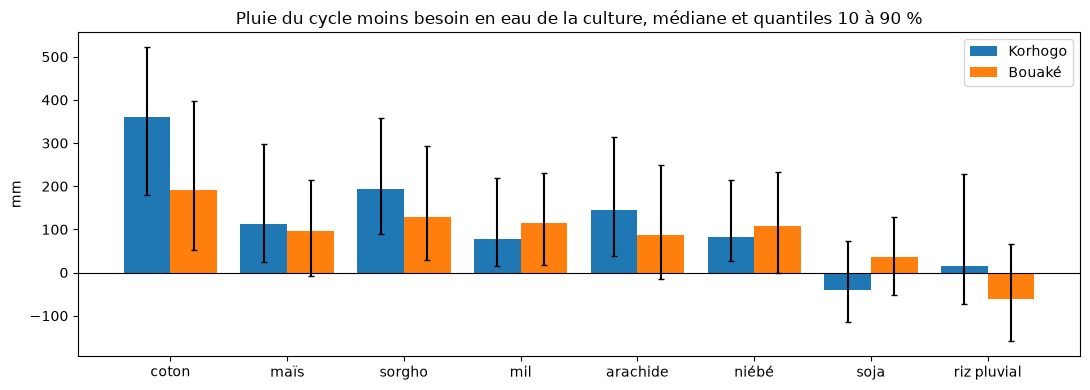

In [5]:
cycles = {i: indicateurs_cultures(d["pluie"], d["meteo"],
                                  evapotranspiration_serie(d["meteo"], LIEUX[i]["lat"], d["altitude"]),
                                  annuels[i]["debut_jour"], courbes_kc_comparees())
          for i, d in donnees.items()}
resumes = {i: resume_cultures(c) for i, c in cycles.items()}
for identifiant, resume in resumes.items():
    print(noms[identifiant])
    display(resume[["duree", "annees", "annees_pluie_sous_besoin", "pluie_cycle_mm mediane", "etc_cycle_mm mediane",
                    "pluie_moins_etc_mm mediane", "pluie_moins_etc_mm q10", "pluie_moins_etc_mm q90",
                    "tmax_moyenne_cycle mediane", "sequence_seche_cycle_jours mediane"]])

figure, axe = plt.subplots(figsize=(11, 4))
largeur = 0.4
for decalage, couleur, (identifiant, resume) in zip([-largeur / 2, largeur / 2], ["C0", "C1"], resumes.items()):
    positions = [k + decalage for k in range(len(resume))]
    mediane = resume["pluie_moins_etc_mm mediane"]
    axe.bar(positions, mediane, width=largeur, color=couleur, label=noms[identifiant],
            yerr=[mediane - resume["pluie_moins_etc_mm q10"], resume["pluie_moins_etc_mm q90"] - mediane], capsize=2)
axe.axhline(0, color="black", linewidth=0.8)
axe.set(title="Pluie du cycle moins besoin en eau de la culture, médiane et quantiles 10 à 90 %", ylabel="mm",
        xticks=range(len(resumes["korhogo"])), xticklabels=resumes["korhogo"].index)
axe.legend()
plt.tight_layout()
plt.show()

**Constat.** En médiane, la pluie du cycle dépasse le besoin en eau de six cultures dans les deux villes, de 360,0 mm pour le coton à Korhogo à 78,3 mm pour le mil à Korhogo. Le soja manque d'eau 15 années sur 25 à Korhogo, avec une médiane de -40,1 mm, et le riz pluvial 18 années sur 25 à Bouaké, avec -60,1 mm. Le besoin du sorgho, 453,1 mm à Korhogo, et celui du mil, 377,6 mm, sont plus faibles que celui du maïs, 481,7 mm.

**Analyse.** Ces indicateurs décrivent le climat que traverse chaque cycle et le besoin d'une culture en conditions standard, pas sa réponse au manque d'eau. Ils comparent le besoin à toute la pluie, sans retirer le ruissellement, et surestiment donc l'eau disponible. L'écart entre cultures dépend beaucoup de leur durée, le mil de 105 jours recevant moins de pluie que le sorgho de 130 jours.

**Décision.** Ces indicateurs alimentent le critère eau de la phase 4, avec leur plage interannuelle. Le soja et le riz pluvial ne conviennent pas à une stratégie centrée sur l'eau.

## 5. Données de surface à venir

**Constat.** SMAP, MODIS MCD12Q1 et MOD13Q1 et SRTM figurent au catalogue d'AppEEARS, qui demande un compte NASA Earthdata.

**Analyse.** Sans ces données, l'outil ne dit rien encore de l'humidité du sol observée, des périodes de sol nu ni de la pente.

**Décision.** Ces indicateurs seront ajoutés à ce notebook dès que les extractions AppEEARS seront disponibles, sur les pixels cultivés de classes 12 et 14 de la couche IGBP de MCD12Q1.